# Data preparation

##### Batch import images from local storage, based on image analysis.
##### the analysis use:
#####   CLIP: OmniBenchMark dataset (about 100 images)
#####   OCR：ICDAR-2019-SROIE dataset (about 300 images)

In [1]:
# batch import images from a folder into the database

import os
import json
import hashlib
import secrets
from PIL import Image as PILImage

from app import app, db, Image
from utils import compute_clip_embedding, extract_ocr_text, auto_categorize_image, allowed_file

def batch_import_images(folder_path, user_id):
    """
    batch import images from a specified folder into the database.
    the logic totaly same as the upload function.

    Args:
        folder_path (str): path to the folder containing images
        user_id (int): ID of the user performing the import(awlays 1 for admin)
    """
    folder_path = os.path.abspath(folder_path)
    print(f"import folder: {folder_path}")

    if not os.path.exists(folder_path):
        print("The folder does not exist.")
        return

    imported_count = 0
    skipped_duplicate = 0
    failed_count = 0

    with app.app_context():
        for filename in os.listdir(folder_path):
            file_path = os.path.join(folder_path, filename)

            if not os.path.isfile(file_path) or not allowed_file(filename):
                continue

            try: 
                with open(file_path, "rb") as f:
                    file_content = f.read()

                file_hash = hashlib.sha256(file_content).hexdigest()
                existing_image = Image.query.filter_by(file_hash=file_hash).first()
                if existing_image:
                    skipped_duplicate += 1
                    print(f"Duplicate file skipping: {filename}")
                    continue
                unique_filename = f"{secrets.token_hex(8)}_{filename}"
                save_path = os.path.join(app.config['UPLOAD_FOLDER'], unique_filename)

                with open(save_path, "wb") as f:
                    f.write(file_content)

                embedding = compute_clip_embedding(save_path)
                embedding_json = json.dumps(embedding.tolist())
                ocr_text = extract_ocr_text(save_path)
                category = auto_categorize_image(save_path)
                
                image = Image(
                    filename=unique_filename,
                    original_filename=filename,
                    file_path=save_path,
                    file_hash=file_hash,
                    file_size=len(file_content),
                    category=category,
                    ocr_text=ocr_text,
                    embedding=embedding_json,
                    user_id=user_id
                )

                db.session.add(image)
                imported_count += 1

            except Exception as e:
                print(f"fail to process {filename}: {e}")
                failed_count += 1

        db.session.commit()

    print("\nImport Summary:")
    print(f"successfully import: {imported_count}")
    print(f"Repeated skip: {skipped_duplicate}")
    print(f"Number of failures: {failed_count}")



[2025-11-22 19:30:37,015] INFO in app: Image Drive startup


In [2]:
# import images for CLIP analysis
batch_import_images("CLIP_image/img", user_id=1)

import folder: D:\homework\25fall\programming\project\project\CLIP_image\img

Import Summary:
successfully import: 94
Repeated skip: 0
Number of failures: 0


In [3]:
# import images for OCR analysis
batch_import_images("OCR/img", user_id=1)

import folder: D:\homework\25fall\programming\project\project\OCR\img
Duplicate file skipping: 015.jpg
Duplicate file skipping: 018.jpg

Import Summary:
successfully import: 299
Repeated skip: 2
Number of failures: 0


### Read srearch log from database

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder
from app import app, db, Image, SearchLog

# get anaysis data
def get_last_n_logs(n=1):
    logs = db.session.query(SearchLog).order_by(SearchLog.timestamp.desc()).limit(n).all()
    if not logs:
        print("No search data found.")
        return []
    if len(logs) < n:
        print(f"Only {len(logs)} logs available (< requested {n}).")
    return logs

def extract_clip_ocr_from_logs(logs):
    clip_results = []  
    ocr_results = []   

    for log in logs:
        topk_data = json.loads(log.topk_results) if log.topk_results else []

        clip_results.append({
            "query": log.query,                                
            "similarities": [x["similarity"] for x in topk_data],
            "topk_ids": [x["image_id"] for x in topk_data]
        })

        # --- OCR ---
        if log.ocr_results:
            ocr_ids = json.loads(log.ocr_results)
        else:
            ocr_ids = []
        ocr_results.append(ocr_ids)

    return clip_results, ocr_results

[2025-11-18 16:08:10,004] INFO in app: Image Drive startup


# CLIP analysis

In [ ]:
# boxplot for multiple queries' similarities
def plot_box(clip_results):
    """
    clip_results: list of dicts, each dict contains:
      - "query": text OR "image:xxx"
      - "similarities": list of floats
    """
    clip_results = list(reversed(clip_results))
    data = []
    labels = []
    
    for entry in clip_results:
        sims = entry.get("similarities", [])
        if not sims:continue

        q = entry.get("query", "")
        if q.startswith("image:"):img_id = q.split("image:")[-1], label = f"IMG {os.path.splitext(img_id)[0]}" 
        else:label = q

        data.append(sims)
        labels.append(label)

    if not data:
        print("No similarity data to plot.")
        return

    # statistics
    all_values = np.concatenate(data)
    sim_min = float(np.min(all_values))
    sim_max = float(np.max(all_values))
    sim_mean = float(np.mean(all_values))

    # plot
    plt.figure(figsize=(10, 6))
    box = plt.boxplot(data, patch_artist=True)
    plt.xticks(range(1, len(labels) + 1), labels, rotation=45, ha='right')
    plt.ylabel("Cosine Similarity")
    plt.title("Similarity Distribution Across Multiple Queries")
    plt.grid(True, linestyle='--', alpha=0.5)
    text_str = f"Min={sim_min:.3f}\nMax={sim_max:.3f}\nMean={sim_mean:.3f}"
    plt.text(0.98, 0.98, text_str, transform=plt.gca().transAxes,
             fontsize=10, verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle="round,pad=0.4", fc="white", alpha=0.7))
    plt.tight_layout()
    plt.show()
    

In [ ]:
# line plot and t-SNE for a single query
def plot_line(similarities):
    if not similarities:
        print("Empty similarity list.")
        return

    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(similarities) + 1), similarities, marker='o')
    plt.title("Cosine Similarity vs. Rank (Top-k)")
    plt.xlabel("Rank")
    plt.ylabel("Similarity")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

def plot_tsne(topk_ids):
    # fetch top-k
    topk_images = db.session.query(Image).filter(Image.id.in_(topk_ids)).all()
    if not topk_images:
        print("No top-k images found.")
        return

    # fetch additional samples (avoid duplicates)
    other_samples = db.session.query(Image).filter(~Image.id.in_(topk_ids)).limit(50).all() #the limit number can be increased when the image database is larger)
    selected_images = topk_images + list(other_samples)

    # extract embeddings
    embeddings = []
    categories = []
    is_topk = []
    for img in selected_images:
        if img.embedding:
            embeddings.append(np.array(json.loads(img.embedding)))
        else:
            embeddings.append(np.zeros(512))
        categories.append(img.category if img.category else 'unknown')
        is_topk.append(img.id in topk_ids)

    embeddings = np.array(embeddings)
    # label encoding
    le = LabelEncoder()
    category_codes = le.fit_transform(categories)
    num_classes = len(le.classes_)

    # choose a colormap with many colors
    if num_classes <= 20:
        cmap = plt.get_cmap('tab20')
    else:
        # generate continuous colormap if categories > 20
        cmap = plt.cm.get_cmap('hsv', num_classes)

    # t-SNE
    perplexity = min(10, len(embeddings) - 1) # the perplexity of t-SNE should not exceed the number of samples; 5-10 is suitable for small samples, the default value is 30 for large samples
    tsne_result = TSNE(n_components=2, random_state=42, perplexity=perplexity).fit_transform(embeddings)

    # plot
    fig, ax = plt.subplots(figsize=(8, 6))

    # markers  
    topk_marker = 'o'   
    other_marker = '^'  

    # set colors and markers
    mask_topk = np.array(is_topk) == True
    ax.scatter(
        tsne_result[mask_topk, 0], tsne_result[mask_topk, 1],
        c='black',                       
        marker=topk_marker,
        s=90, alpha=0.9,
        edgecolors='white',
        label='Top-k'
    )
    

    mask_other = np.array(is_topk) == False
    ax.scatter(
        tsne_result[mask_other, 0], tsne_result[mask_other, 1],
        c=category_codes[mask_other],      
        cmap=cmap,
        marker=other_marker,
        s=80, alpha=0.8,
        edgecolors='gray',
        label='Other'
    )

    ax.set_xlabel("t-SNE Dim 1")
    ax.set_ylabel("t-SNE Dim 2")
    ax.set_title("t-SNE Visualization (Top-k Highlighted)")

    # colorbar only for categories of "Other"
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=num_classes - 1))
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, ticks=np.arange(num_classes))
    cbar.set_ticklabels(le.classes_)
    cbar.set_label("Category (Other Samples)")

    ax.legend()
    plt.show()



In [46]:
# run clip analysis
def clip_analysis(n_logs=1):
    with app.app_context():
        logs = get_last_n_logs(n_logs)
        if not logs:
            return

        clip_results, ocr_results = extract_clip_ocr_from_logs(logs)

        # boxplot (multiple queries)
        if n_logs > 1:
            plot_box(clip_results)

        # for a single log
        if len(clip_results) == 1:
            similarities = clip_results[0]["similarities"]
            topk_ids = clip_results[0]["topk_ids"]
            plot_line(similarities)
            plot_tsne(topk_ids)

        #return clip_results, ocr_results


### run clip_analysis() for analysing
#### Only the most recent n queries can be analyzed, where n is the input value of the analysis function (clip_analysis(n) and the is same in ocr_analysis(n)).
##### search by text. query:"tree"

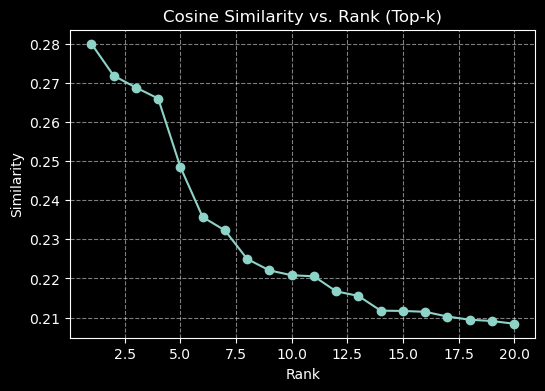

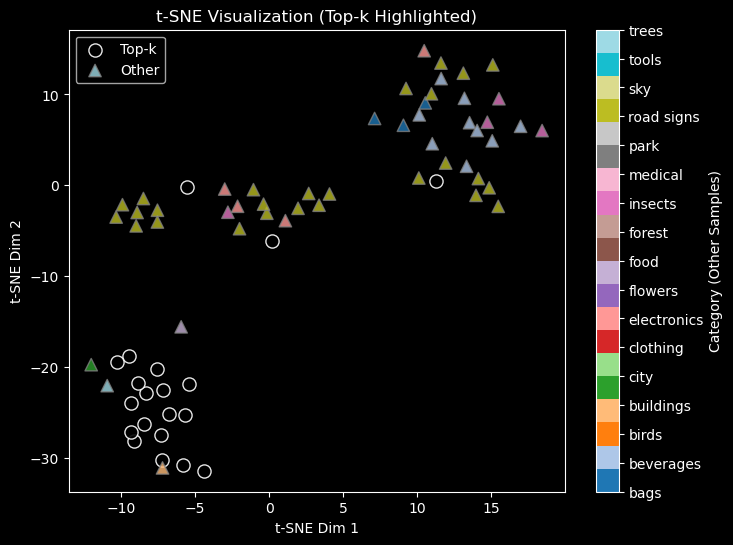

In [72]:
# single clip search
clip_analysis()

#### search by text: multiple clip searches

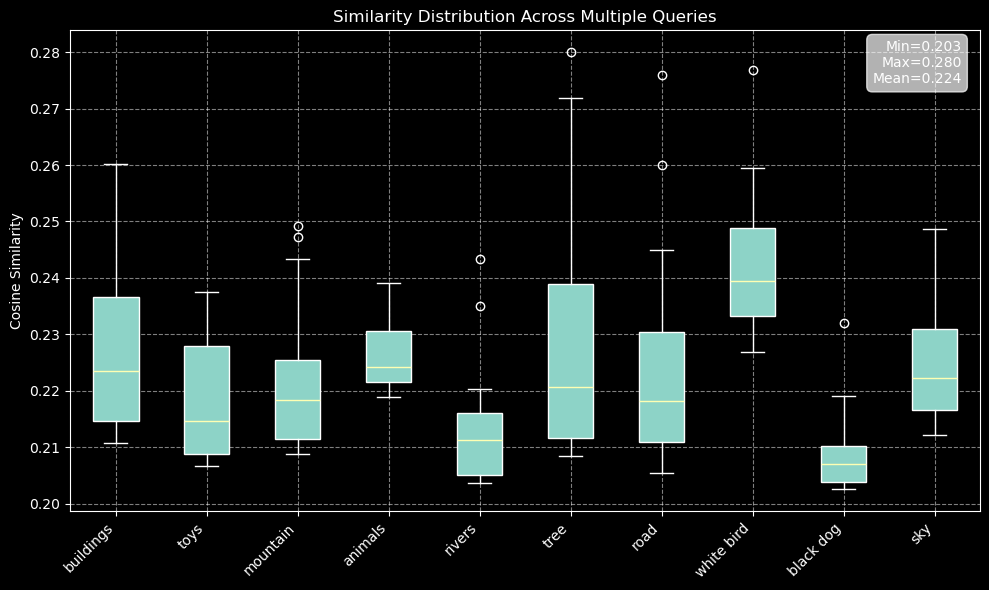

In [73]:
# multiple clip searches
clip_analysis(10)

#### search by image. use a bird photo.

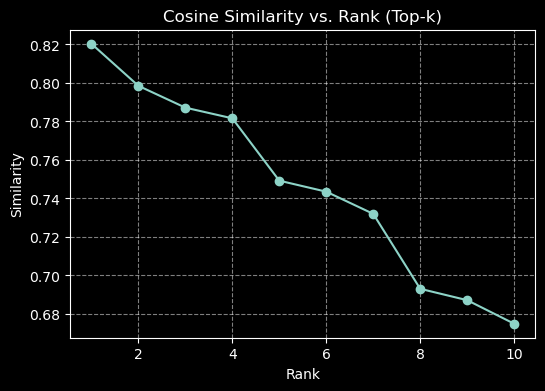

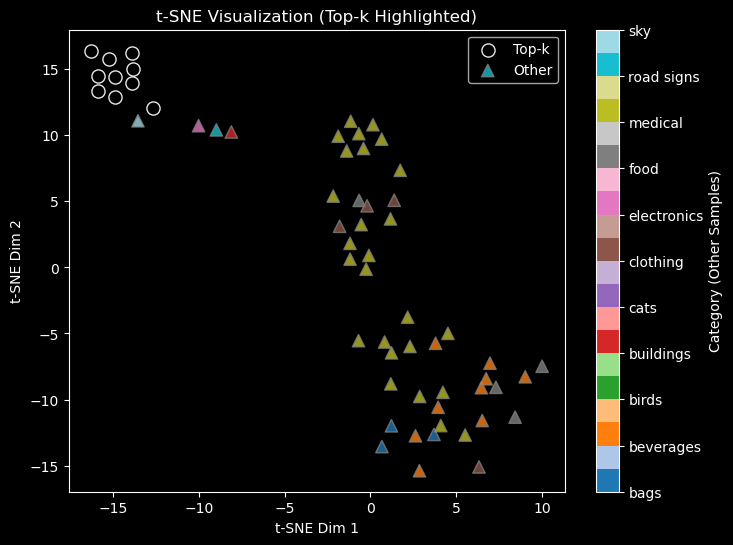

In [70]:
# single clip search: the last query
clip_analysis()

#### search by image: mutiple clip searches

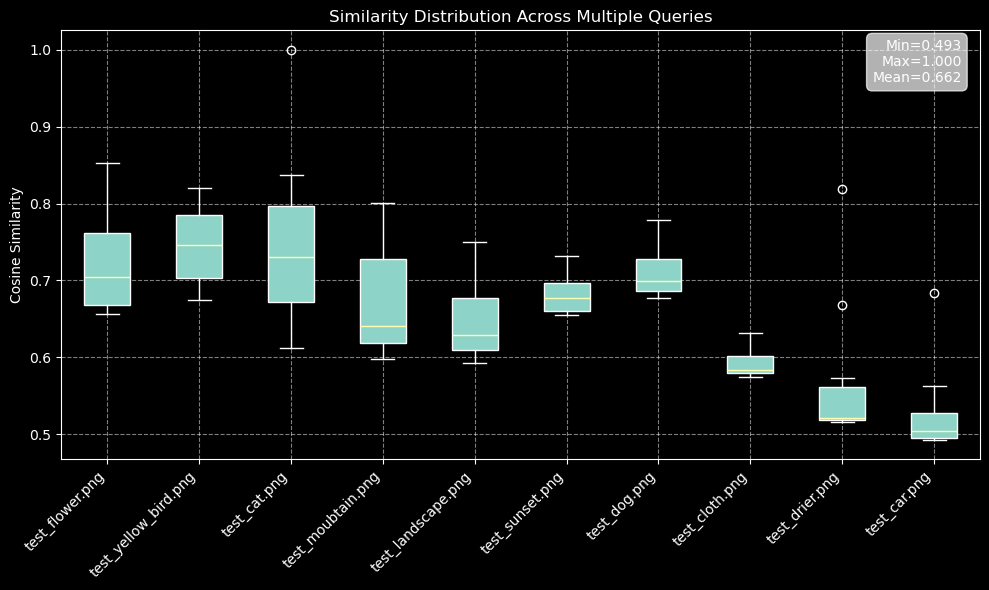

In [71]:
# multiple clip searches
clip_analysis(10)

# OCR analysis
#### To ensure accuracy, it's best to use the words in the key folder as your search terms.

In [63]:

def ocr_get_result_filename(log):
    actual_ids = json.loads(log.ocr_results) if log.ocr_results else []
    rows = db.session.query(Image).filter(Image.id.in_(actual_ids)).all()
    return [os.path.splitext(img.original_filename)[0] for img in rows]

#  OCR-hit set from FULL database
def ocr_get_hit_set(query):
    all_rows = db.session.query(Image).all()
    return {
        os.path.splitext(img.original_filename)[0]
        for img in all_rows
        if query.lower() in (img.ocr_text or "").lower() # check if query in OCR text in python instead of SQL
    }


# ground truth
"""
use some images and key information in ICDAR dataset to test OCR retrieval performance
https://github.com/zzzDavid/ICDAR-2019-SROIE
if want to test all information in image, download the box folder from the above link
"""
def ocr_get_ground_truth(query, key_dir="OCR/key"):
    
    """
    search key files to find JSONs containing the search term query,
    and return the corresponding image names (without extension).
    (in the test dataset,the filename of image is the same as the json file name)
    """
    matched = []
    for filename in os.listdir(key_dir):
        if filename.endswith(".json"):
            data = json.load(open(os.path.join(key_dir, filename), "r", encoding="utf-8"))
            if query.lower() in json.dumps(data).lower():
                matched.append(os.path.splitext(filename)[0])
    return matched

def ocr_compute_metrics(actual_names, ocr_hit_set, ground_truth_names):
    G = set(ground_truth_names)
    S = set(actual_names)
    O = set(ocr_hit_set)

    TP = len(G & S)
    FP = len(S - G)
    FN = len(G - S)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

    ocr_recall = len(G & O) / len(G) if len(G) > 0 else 0
    search_within_ocr_recall = len(G & S) / len(G & O) if len(G & O) > 0 else 0

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "ocr_recall": ocr_recall,
        "search_recall": search_within_ocr_recall
    }


# visulization of recall comparison: to figure out the bottleneck of OCR-based retrieval
# OCR recall * search recall = overall recall
def ocr_plot_metrics(metrics, title_suffix=""):
    recall_values = [metrics["recall"], metrics["search_recall"], metrics["ocr_recall"]][::-1]

    labels = ['Overall Recall', 'Search Recall', 'OCR Recall'][::-1]

    plt.figure(figsize=(8, 3))
    bars = plt.barh(labels, recall_values, color=plt.cm.tab10.colors[:3])
    plt.xlim(0, 1)
    plt.xlabel("Recall")
    plt.title(f"Recall Comparison {title_suffix}")

    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{width:.2f}", va='center')

    plt.tight_layout()
    plt.show()

# compute aggregate metrics over multiple searches
def ocr_aggregate_multi_results(metrics_list):
    keys = ["precision", "recall", "f1", "ocr_recall", "search_recall"]

    agg = {}
    for k in keys:
        values = [m[k] for m in metrics_list]
        agg[k] = {
            "min": min(values),
            "max": max(values),
            "avg": sum(values) / len(values) if len(values) > 0 else 0
        }

    return agg

def ocr_ouput_table(queries, metrics_list, show_avg=False):
    """
    queries: ["apple", "tax", ...]
    metrics_list: [ {"precision":..., "recall":..., "f1":...}, ... ]
    show_avg: 是否增加平均值
    """

    # 表头
    header = f"{'Query':<15} {'Precision':<12} {'Recall':<12} {'F1':<12}"
    lines = [header, "-" * len(header)]

    # 每一行
    for q, m in zip(queries, metrics_list):
        line = f"{q:<15} {m['precision']:<12.4f} {m['recall']:<12.4f} {m['f1']:<12.4f}"
        lines.append(line)

    # 添加平均值
    if show_avg:
        avg_p = sum(m["precision"] for m in metrics_list) / len(metrics_list)
        avg_r = sum(m["recall"] for m in metrics_list) / len(metrics_list)
        avg_f = sum(m["f1"] for m in metrics_list) / len(metrics_list)

        lines.append("-" * len(header))
        lines.append(f"{'AVG':<15} {avg_p:<12.4f} {avg_r:<12.4f} {avg_f:<12.4f}")

    return "\n".join(lines)


In [64]:
def ocr_analysis(n_logs=1):
    with app.app_context():
        logs = get_last_n_logs(n_logs)   
        if not logs:
            print("No search data found.")
            exit()

        is_multi = len(logs) > 1

        metrics_list = []

        for log in logs:
            query = log.query

            actual_names = ocr_get_result_filename(log)
            ocr_hit_set = ocr_get_hit_set(query)
            ground_truth = ocr_get_ground_truth(query)

            metrics = ocr_compute_metrics(actual_names, ocr_hit_set, ground_truth)
            metrics_list.append(metrics)

            if not is_multi:
                print(ocr_ouput_table([query], [metrics]))
                ocr_plot_metrics(metrics)
                
        
        if is_multi:
            agg = ocr_aggregate_multi_results(metrics_list)
            
            queries = [log.query for log in logs]
            print(ocr_ouput_table(queries, metrics_list, show_avg=True))

            avg_metrics = {
                "precision": None, 
                "recall": agg["recall"]["avg"],
                "ocr_recall": agg["ocr_recall"]["avg"],
                "search_recall": agg["search_recall"]["avg"],
                "f1": None
            }
            ocr_plot_metrics(avg_metrics, title_suffix="(Average)")


### result analysis
#### search term: "BHD"

Query           Precision    Recall       F1          
------------------------------------------------------
BHD             0.9811       0.3399       0.5049      


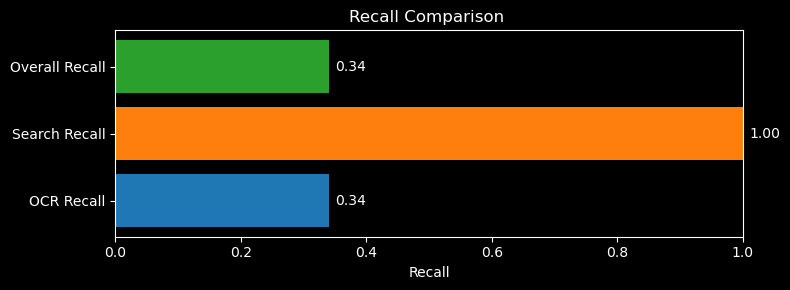

In [ ]:
# single OCR search
ocr_analysis()

#### mutiple OCR searches

Query           Precision    Recall       F1          
------------------------------------------------------
BLOCK           1.0000       0.3333       0.5000      
MALAYSIA        1.0000       0.2333       0.3784      
47.5            0.0000       0.0000       0.0000      
60              0.2742       0.4146       0.3301      
COMPANY         1.0000       0.0266       0.0518      
BHD             0.9811       0.3399       0.5049      
ALAN            0.9872       0.3105       0.4724      
SAM             1.0000       1.0000       1.0000      
MONTOR          0.0000       0.0000       0.0000      
TRADING         1.0000       0.4667       0.6364      
------------------------------------------------------
AVG             0.7243       0.3125       0.3874      


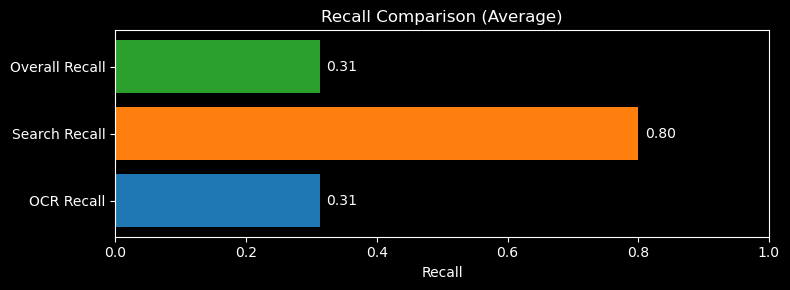

In [67]:
# mutiple OCR searches
ocr_analysis(10)